# EDA Data_1: масштабирование и подготовка к кластеризации

Цель ноутбука:
- сделать быстрый, но воспроизводимый EDA по `Data_1`;
- проверить, какое преобразование числовых признаков лучше подходит для кластеризации;
- получить практический вывод по `RobustScaler`, `PCA` и `log1p`.

## 1. Импорты и конфигурация

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.vq import kmeans2
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

warnings.filterwarnings("ignore", message="One of the clusters is empty")
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "Data_1").exists() and (PROJECT_ROOT.parent / "Data_1").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "Data_1"
assert DATA_DIR.exists(), f"Data_1 не найден: {DATA_DIR}"

FILES_TO_USE = 10
ROWS_PER_FILE = 100_000

NUMERIC_FEATURES = [
    "txn_cnt",
    "unique_txn_cnt",
    "unique_merchants",
    "unique_mcc",
    "active_days",
    "avg_txn_per_active_day",
]

## 2. Загрузка Data_1 и построение user-level числовых признаков

In [3]:
def load_raw_transactions(data_dir: Path, files_to_use: int, rows_per_file: int) -> pl.DataFrame:
    files = sorted(data_dir.glob("*.csv"))[:files_to_use]
    frames = []

    schema_overrides = {
        "real_transaction_dttm": pl.Utf8,
        "party_rk": pl.Utf8,
        "transaction_rk": pl.Utf8,
        "merchant_type_code": pl.Int32,
        "merchant_nm": pl.Utf8,
        "category_nm": pl.Utf8,
    }

    for file_path in files:
        frames.append(pl.read_csv(file_path, n_rows=rows_per_file, schema_overrides=schema_overrides))

    raw = pl.concat(frames, how="vertical_relaxed")
    raw = raw.with_columns(
        pl.col("real_transaction_dttm")
        .str.strptime(pl.Datetime, format="%Y-%m-%d %H:%M:%S", strict=False)
        .alias("dt")
    ).with_columns(pl.col("dt").dt.truncate("1d").alias("txn_date"))
    return raw


def build_user_numeric_features(raw: pl.DataFrame) -> pd.DataFrame:
    user = (
        raw.group_by("party_rk")
        .agg(
            pl.len().alias("txn_cnt"),
            pl.col("transaction_rk").n_unique().alias("unique_txn_cnt"),
            pl.col("merchant_nm").n_unique().alias("unique_merchants"),
            pl.col("merchant_type_code").n_unique().alias("unique_mcc"),
            pl.col("txn_date").n_unique().alias("active_days"),
        )
        .with_columns(
            (
                pl.col("txn_cnt")
                / pl.when(pl.col("active_days") > 0)
                .then(pl.col("active_days"))
                .otherwise(1)
            ).alias("avg_txn_per_active_day")
        )
    )
    return user.to_pandas()


raw_df = load_raw_transactions(DATA_DIR, FILES_TO_USE, ROWS_PER_FILE)
user_df = build_user_numeric_features(raw_df)

print(f"raw rows: {raw_df.height:,}")
print(f"unique users: {user_df.shape[0]:,}")
user_df[NUMERIC_FEATURES].describe().T

raw rows: 1,000,000
unique users: 29,924


,count,mean,std,min,25%,50%,75%,max
txn_cnt,29924.0,33.417992,41.976141,1.0,4.0,17.00,49.000,1306.000000
unique_txn_cnt,29924.0,33.417992,41.976141,1.0,4.0,17.00,49.000,1306.000000
unique_merchants,29924.0,15.755948,16.944640,1.0,3.0,10.00,23.000,162.000000
unique_mcc,29924.0,8.162278,7.039236,1.0,2.0,6.00,12.000,51.000000
active_days,29924.0,11.938578,9.266475,1.0,3.0,10.00,20.000,28.000000
avg_txn_per_active_day,29924.0,2.118003,1.353525,1.0,1.0,1.75,2.625,62.190476


## 3. Базовый EDA: асимметрия и выбросы

In [4]:
stats = user_df[NUMERIC_FEATURES].copy()
q = stats.quantile([0.25, 0.50, 0.75, 0.95, 0.99]).T
q.columns = ["q25", "q50", "q75", "q95", "q99"]
q["iqr"] = q["q75"] - q["q25"]
q["upper_iqr"] = q["q75"] + 1.5 * q["iqr"]
q["outlier_share_upper"] = [
    float((stats[col] > q.loc[col, "upper_iqr"]).mean()) for col in stats.columns
]
q["skew"] = stats.skew(numeric_only=True)
q["p99_over_median"] = q["q99"] / q["q50"].replace(0, np.nan)

q.sort_values("outlier_share_upper", ascending=False)

,q25,q50,q75,q95,q99,iqr,upper_iqr,outlier_share_upper,skew,p99_over_median
txn_cnt,4.0,17.00,49.000,116.000000,179.000000,45.000,116.5000,0.049492,3.170974,10.529412
unique_txn_cnt,4.0,17.00,49.000,116.000000,179.000000,45.000,116.5000,0.049492,3.170974,10.529412
unique_merchants,3.0,10.00,23.000,49.000000,73.000000,20.000,53.0000,0.038264,1.820235,7.300000
avg_txn_per_active_day,1.0,1.75,2.625,4.571429,6.740741,1.625,5.0625,0.034989,5.211894,3.851852
unique_mcc,2.0,6.00,12.000,22.000000,30.000000,10.000,27.0000,0.016676,1.241358,5.000000
active_days,3.0,10.00,20.000,27.000000,28.000000,17.000,45.5000,0.000000,0.344301,2.800000


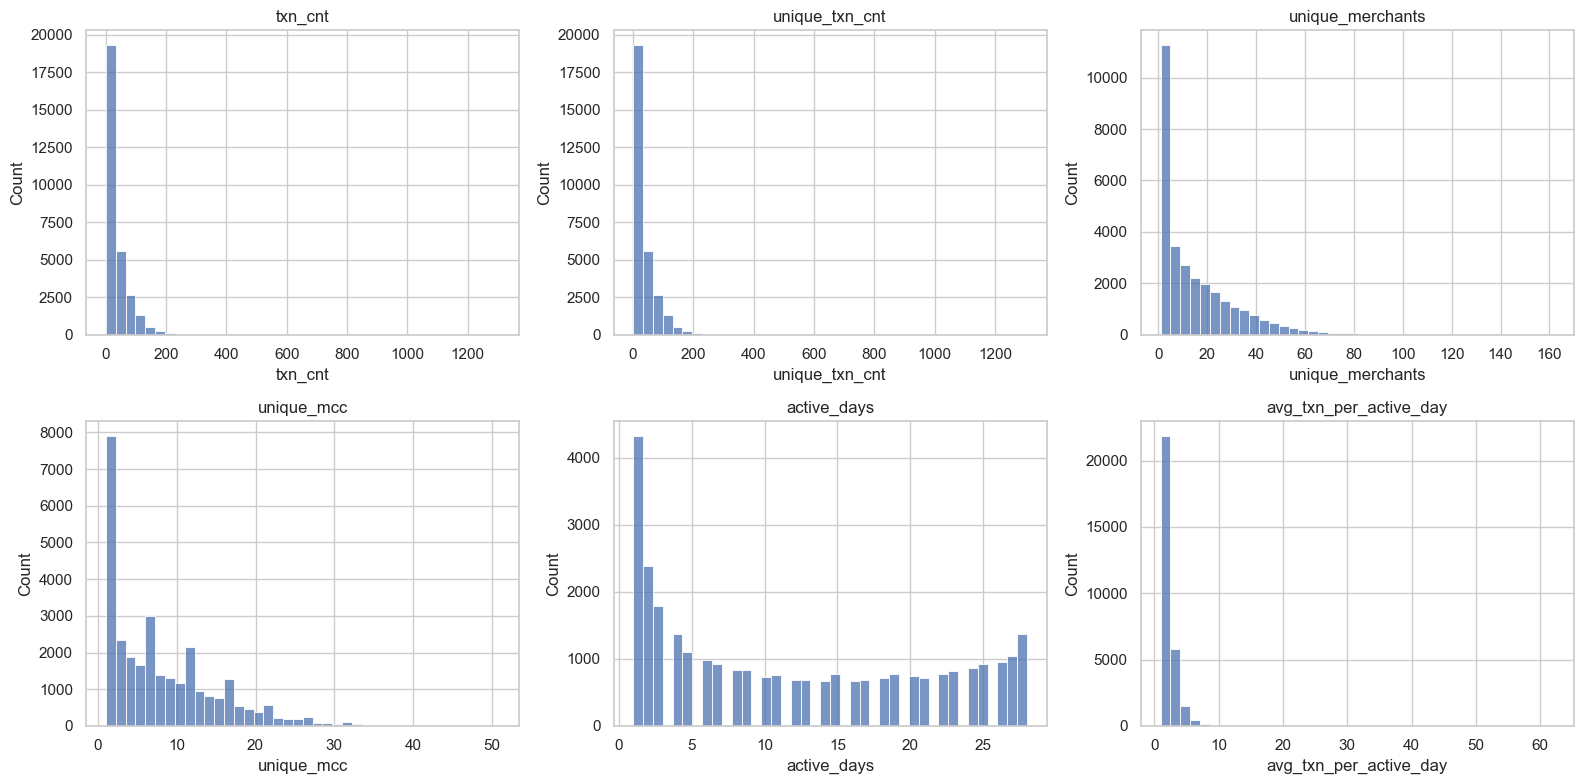

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(user_df[col], bins=40, kde=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()

## 4. Почему для этих признаков подходит именно RobustScaler

Сравним чувствительность `StandardScaler` и `RobustScaler` к хвостам распределения через stress-test:
- берем топ 0.5% пользователей по `txn_cnt`;
- усиливаем им числовые значения в 4 раза;
- смотрим, насколько меняется параметр `scale_` у каждого скейлера.

In [6]:
X = user_df[NUMERIC_FEATURES].astype(float)

std = StandardScaler().fit(X)
rob = RobustScaler().fit(X)

X_aug = X.copy()
top_idx = X_aug.nlargest(max(1, int(len(X_aug) * 0.005)), "txn_cnt").index
mult_cols = ["txn_cnt", "unique_txn_cnt", "unique_merchants", "unique_mcc", "avg_txn_per_active_day"]
X_aug.loc[top_idx, mult_cols] = X_aug.loc[top_idx, mult_cols] * 4

std_aug = StandardScaler().fit(X_aug)
rob_aug = RobustScaler().fit(X_aug)

scale_sensitivity = pd.DataFrame(
    {
        "feature": NUMERIC_FEATURES,
        "std_scale_change_pct": (std_aug.scale_ - std.scale_) / std.scale_ * 100,
        "robust_scale_change_pct": (rob_aug.scale_ - rob.scale_) / rob.scale_ * 100,
    }
)
scale_sensitivity

,feature,std_scale_change_pct,robust_scale_change_pct
0,txn_cnt,110.383152,0.0
1,unique_txn_cnt,110.383152,0.0
2,unique_merchants,67.093111,0.0
3,unique_mcc,49.932014,0.0
4,active_days,0.000000,0.0
5,avg_txn_per_active_day,136.782252,0.0


### $\implies$ Берем не SScaler а RScaler

## 5. Почему `log1p` для наших числовых фичей не нужен

Проверим, насколько `log1p` сжимает различия в верхнем хвосте (а именно там часто лежит сегментационная ценность для активных пользователей).

In [7]:
log_compression_rows = []
for col in NUMERIC_FEATURES:
    s = X[col]
    slog = np.log1p(s)

    raw_p99_p50 = float(s.quantile(0.99) - s.quantile(0.50))
    log_p99_p50 = float(slog.quantile(0.99) - slog.quantile(0.50))

    raw_p99_p95 = float(s.quantile(0.99) - s.quantile(0.95))
    log_p99_p95 = float(slog.quantile(0.99) - slog.quantile(0.95))

    log_compression_rows.append(
        {
            "feature": col,
            "raw_p99_p50": raw_p99_p50,
            "log_p99_p50": log_p99_p50,
            "compression_p99_p50_pct": (1 - log_p99_p50 / raw_p99_p50) * 100 if raw_p99_p50 else np.nan,
            "raw_p99_p95": raw_p99_p95,
            "log_p99_p95": log_p99_p95,
            "compression_p99_p95_pct": (1 - log_p99_p95 / raw_p99_p95) * 100 if raw_p99_p95 else np.nan,
        }
    )

log_compression_df = pd.DataFrame(log_compression_rows)
log_compression_df

,feature,raw_p99_p50,log_p99_p50,compression_p99_p50_pct,raw_p99_p95,log_p99_p95,compression_p99_p95_pct
0,txn_cnt,162.000000,2.302585,98.578651,63.000000,0.430783,99.316218
1,unique_txn_cnt,162.000000,2.302585,98.578651,63.000000,0.430783,99.316218
2,unique_merchants,63.000000,1.906170,96.974334,24.000000,0.392042,98.366491
3,unique_mcc,24.000000,1.488077,93.799679,8.000000,0.298493,96.268838
4,active_days,18.000000,0.969401,94.614441,1.000000,0.035091,96.490868
5,avg_txn_per_active_day,4.990741,1.034896,79.263670,2.169312,0.328846,84.841007


## 6. Проверка влияния `PCA` и `log1p` на структуру кластеризации

Важный момент: сравниваем качество кластерных разбиений **в исходном пространстве RobustScaled-фичей**, чтобы оценить, насколько трансформация искажает исходную геометрию данных.

In [8]:
def best_kmeans2_labels(arr: np.ndarray, n_clusters: int = 6, n_init: int = 10, seed: int = 42):
    local_rng = np.random.default_rng(seed)
    best_labels = None
    best_inertia = np.inf

    for _ in range(n_init):
        init_idx = local_rng.choice(arr.shape[0], size=n_clusters, replace=False)
        init_centroids = arr[init_idx]
        centroids, labels = kmeans2(arr, init_centroids, iter=60, minit="matrix")
        inertia = ((arr - centroids[labels]) ** 2).sum()
        if inertia < best_inertia:
            best_inertia = inertia
            best_labels = labels
    return best_labels


X_rob = RobustScaler().fit_transform(X)

X_log = X.copy()
for col in NUMERIC_FEATURES:
    if (X_log[col] >= 0).all():
        X_log[col] = np.log1p(X_log[col])
X_log_rob = RobustScaler().fit_transform(X_log)

X_std = StandardScaler().fit_transform(X)
pca95 = PCA(n_components=0.95, random_state=RANDOM_SEED)
X_rob_pca95 = pca95.fit_transform(X_rob)

cluster_variants = {
    "robust_base": X_rob,
    "standard": X_std,
    "log1p_robust": X_log_rob,
    "pca95_robust": X_rob_pca95,
}

rows = []
for name, arr in cluster_variants.items():
    sils = []
    dbs = []
    for seed in [11, 22, 33, 44, 55]:
        labels = best_kmeans2_labels(arr, n_clusters=6, n_init=10, seed=seed)
        sil = silhouette_score(X_rob, labels, sample_size=min(8000, len(labels)), random_state=seed)
        db = davies_bouldin_score(X_rob, labels)
        sils.append(sil)
        dbs.append(db)

    rows.append(
        {
            "variant": name,
            "sil_mean_on_robust_space": float(np.mean(sils)),
            "sil_std": float(np.std(sils)),
            "db_mean_on_robust_space": float(np.mean(dbs)),
            "db_std": float(np.std(dbs)),
        }
    )

cluster_eval_df = pd.DataFrame(rows).sort_values("sil_mean_on_robust_space", ascending=False)
cluster_eval_df

,variant,sil_mean_on_robust_space,sil_std,db_mean_on_robust_space,db_std
3,pca95_robust,0.442337,0.003470,0.901799,0.006938
0,robust_base,0.437568,0.005823,0.906307,0.009399
1,standard,0.417340,0.004477,0.921513,0.012378
2,log1p_robust,0.290570,0.011550,1.114631,0.006046


In [9]:
def knn_overlap(base: np.ndarray, transformed: np.ndarray, k: int = 20, sample_size: int = 5000, seed: int = 42) -> float:
    local_rng = np.random.default_rng(seed)
    n = base.shape[0]
    idx = local_rng.choice(n, size=min(sample_size, n), replace=False)

    nn_base = NearestNeighbors(n_neighbors=k + 1).fit(base)
    nn_tr = NearestNeighbors(n_neighbors=k + 1).fit(transformed)

    neigh_base = nn_base.kneighbors(base[idx], return_distance=False)[:, 1:]
    neigh_tr = nn_tr.kneighbors(transformed[idx], return_distance=False)[:, 1:]

    overlaps = [len(set(a).intersection(set(b))) / k for a, b in zip(neigh_base, neigh_tr)]
    return float(np.mean(overlaps))


neighbor_df = pd.DataFrame(
    {
        "transform": ["log1p + robust", "pca95 + robust"],
        "knn_overlap_vs_robust_base": [
            knn_overlap(X_rob, X_log_rob, k=20, sample_size=5000, seed=RANDOM_SEED),
            knn_overlap(X_rob, X_rob_pca95, k=20, sample_size=5000, seed=RANDOM_SEED),
        ],
    }
)
neighbor_df

,transform,knn_overlap_vs_robust_base
0,log1p + robust,0.79520
1,pca95 + robust,0.33477


In [10]:
explained = pd.DataFrame(
    {
        "component": np.arange(1, len(pca95.explained_variance_ratio_) + 1),
        "explained_variance_ratio": pca95.explained_variance_ratio_,
        "cum_explained_variance": np.cumsum(pca95.explained_variance_ratio_),
    }
)
explained

,component,explained_variance_ratio,cum_explained_variance
0,1,0.892010,0.892010
1,2,0.064676,0.956685


## 7. Выводы для пайплайна

По результатам EDA и проверок:

1. Для наших числовых transaction-фич используем `RobustScaler`.
   - распределения с правыми хвостами и выбросами;
   - stress-test показывает высокую чувствительность `StandardScaler` к хвостам и практически нулевую у `RobustScaler`.

2. `log1p` для этих числовых фич не применяем.
   - `log1p` сильно сжимает верхний хвост (часто >80-95%), из-за чего теряется различимость активных пользователей;
   - при оценке кластерных меток в исходном robust-пространстве качество (`silhouette`, `DB`) ухудшается.

3. `PCA` для кластеризации не применяем.
   - по метрикам в исходном robust-пространстве прироста качества нет, местами есть деградация;
   - наблюдается потеря локальной структуры соседств (`kNN overlap`), плюс снижение интерпретируемости кластеров.

Итог: текущая стратегия без `PCA` и без `log1p`, но с `RobustScaler`, подтверждается преданализом.